# Caso 03 — NidoHogar, portal inmobiliario: del clic al contrato
## Día 3 — La Primera Grieta: El Destacado Convierte un 38 % Peor a Contrato

**Objetivo analítico del Día 3:**
Romper la ilusión de la media global (`6,54 %` de conversión de contacto a contrato) abriendo el embudo por `tipo_anuncio`:
1. **La Paradoja:** Comprobar que el anuncio `destacado` casi dobla en contactos al `normal`, pero **convierte un `37,6 %` peor a contrato (`4,98 %` vs `7,98 %`)**.
2. **Las Barras Cruzadas:** Visualizar el choque entre la métrica de Comercial (contactos/anuncio) y la métrica de Negocio (conversión a contrato).
3. **Abogado del Diablo (Descarte de explicaciones fáciles):** Verificar si la peor conversión del destacado se explica por el `canal` de contacto, la `ciudad`, el `tipo_anunciante` o el `tramo_precio`.
4. **El Dinero en Juego:** Cuantificar las comisiones totales que aporta cada tipo de anuncio a la cuenta de resultados de NidoHogar.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
con = duckdb.connect()

for tabla in ['anuncios', 'visitas', 'contactos', 'contratos', 'agencias', 'zonas']:
    con.execute(f"CREATE OR REPLACE VIEW v_{tabla} AS SELECT * FROM read_csv_auto('data/clean/{tabla}_clean.csv')")

# 1. La Grieta: Embudo completo desagregado por tipo_anuncio
q_grieta = """
WITH v_por_a AS (
    SELECT anuncio_id, COUNT(*) AS n_visitas FROM v_visitas GROUP BY anuncio_id
),
c_por_a AS (
    SELECT anuncio_id, COUNT(*) AS n_contactos FROM v_contactos GROUP BY anuncio_id
),
ct_por_a AS (
    SELECT anuncio_id, COUNT(*) AS n_contratos, SUM(comision) AS comision_total FROM v_contratos GROUP BY anuncio_id
)
SELECT
    a.tipo_anuncio,
    COUNT(DISTINCT a.anuncio_id) AS anuncios,
    SUM(COALESCE(v.n_visitas, 0)) AS visitas_totales,
    ROUND(AVG(v.n_visitas), 2) AS visitas_por_anuncio,
    SUM(COALESCE(c.n_contactos, 0)) AS contactos_totales,
    ROUND(AVG(c.n_contactos), 2) AS contactos_por_anuncio,
    ROUND(SUM(COALESCE(c.n_contactos, 0)) * 100.0 / SUM(COALESCE(v.n_visitas, 0)), 2) AS tasa_visita_a_contacto_pct,
    SUM(COALESCE(ct.n_contratos, 0)) AS contratos_cerrados,
    ROUND(SUM(COALESCE(ct.n_contratos, 0)) * 100.0 / SUM(COALESCE(c.n_contactos, 0)), 2) AS tasa_contacto_a_contrato_pct,
    ROUND(SUM(COALESCE(ct.n_contratos, 0)) * 100.0 / SUM(COALESCE(v.n_visitas, 0)), 2) AS tasa_visita_a_contrato_pct
FROM v_anuncios a
LEFT JOIN v_por_a v USING (anuncio_id)
LEFT JOIN c_por_a c USING (anuncio_id)
LEFT JOIN ct_por_a ct USING (anuncio_id)
GROUP BY a.tipo_anuncio
ORDER BY tasa_contacto_a_contrato_pct DESC;
"""
df_grieta = con.execute(q_grieta).df()
print("=== 1. LA PARADOJA DEL EMBUDO POR TIPO DE ANUNCIO ===")
display(df_grieta)

=== 1. LA PARADOJA DEL EMBUDO POR TIPO DE ANUNCIO ===


,tipo_anuncio,anuncios,visitas_totales,visitas_por_anuncio,contactos_totales,contactos_por_anuncio,tasa_visita_a_contacto_pct,contratos_cerrados,tasa_contacto_a_contrato_pct,tasa_visita_a_contrato_pct
0,normal,3211,28742.0,8.95,9270.0,3.05,32.25,740.0,7.98,2.57
1,destacado,1489,26533.0,17.82,8610.0,5.79,32.45,429.0,4.98,1.62


### Análisis de la Paradoja: Dónde se Rompe el Embudo del Destacado
* **Arriba del embudo (Visitas $\rightarrow$ Contactos):** La conversión de visita a contacto es **idéntica** en ambos productos (**`32,45 %` en destacado vs `32,25 %` en normal**). Como el destacado recibe el doble de visitas (`17,82` vs `8,95`), genera casi el doble de contactos (`5,79` vs `3,05`).
* **Abajo del embudo (Contactos $\rightarrow$ Contratos):** Aquí aparece la grieta:
  * **`normal`:** De **`9.270` contactos** cierra **`740` contratos** $\rightarrow$ **Tasa de conversión del `7,98 %`**.
  * **`destacado`:** De **`8.610` contactos** cierra solo **`429` contratos** $\rightarrow$ **Tasa de conversión del `4,98 %`** (**$-3,00\text{ pp}$**, un **`37,6 %` menos de efectividad por contacto**).

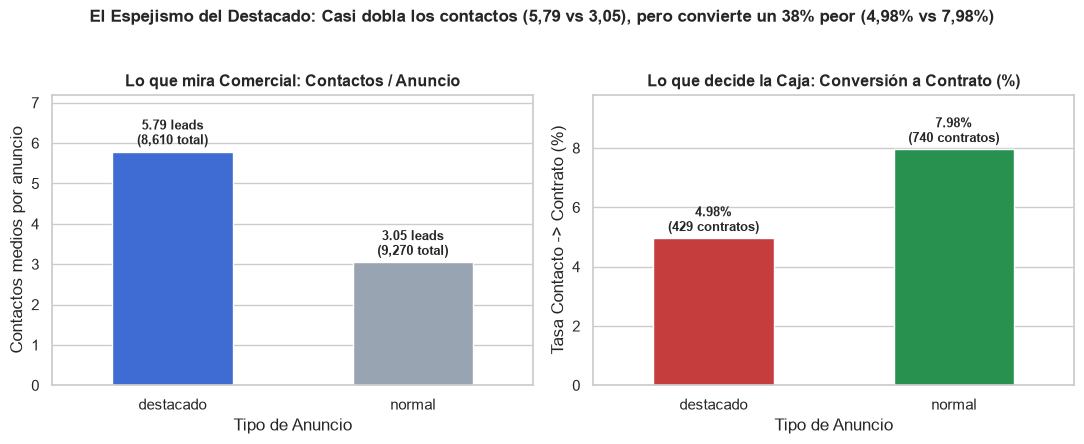

In [2]:
# 2. Las Barras Cruzadas: Contactos por Anuncio vs Tasa de Conversión a Contrato (%)
df_plot = df_grieta.sort_values('tipo_anuncio', ascending=True).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
sns.barplot(
    data=df_plot, x='tipo_anuncio', y='contactos_por_anuncio',
    hue='tipo_anuncio', palette={'destacado': '#2563eb', 'normal': '#94a3b8'},
    legend=False, width=0.5, ax=axes[0]
)
axes[0].set_title('Lo que mira Comercial: Contactos / Anuncio', fontsize=11.5, fontweight='bold')
axes[0].set_ylabel('Contactos medios por anuncio')
axes[0].set_xlabel('Tipo de Anuncio')
axes[0].set_ylim(0, 7.2)
for i, r in enumerate(df_plot.itertuples()):
    axes[0].text(i, r.contactos_por_anuncio + 0.18, f"{r.contactos_por_anuncio:.2f} leads\n({int(r.contactos_totales):,} total)", ha='center', fontweight='bold', fontsize=9.5)

sns.barplot(
    data=df_plot, x='tipo_anuncio', y='tasa_contacto_a_contrato_pct',
    hue='tipo_anuncio', palette={'destacado': '#dc2626', 'normal': '#16a34a'},
    legend=False, width=0.5, ax=axes[1]
)
axes[1].set_title('Lo que decide la Caja: Conversión a Contrato (%)', fontsize=11.5, fontweight='bold')
axes[1].set_ylabel('Tasa Contacto -> Contrato (%)')
axes[1].set_xlabel('Tipo de Anuncio')
axes[1].set_ylim(0, 9.8)
for i, r in enumerate(df_plot.itertuples()):
    axes[1].text(i, r.tasa_contacto_a_contrato_pct + 0.22, f"{r.tasa_contacto_a_contrato_pct:.2f}%\n({int(r.contratos_cerrados)} contratos)", ha='center', fontweight='bold', fontsize=9.5)

plt.suptitle('El Espejismo del Destacado: Casi dobla los contactos (5,79 vs 3,05), pero convierte un 38% peor (4,98% vs 7,98%)', fontsize=12.5, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### Análisis Visual de las Barras Cruzadas
* El gráfico enfrenta las dos verdades parciales de la compañía: en el panel izquierdo (`Contactos / Anuncio`), `destacado` gana claramente (`5,79` vs `3,05`), lo que alimenta el entusiasmo de Gonzalo Prieto; en el panel derecho (`Tasa Contacto -> Contrato`), las barras se invierten por completo y `normal` supera a `destacado` por **`7,98 %` frente a `4,98 %`**.

In [3]:
# 3. Abogado del Diablo: ¿Se explica la grieta por Canal, Ciudad, Tipo de Anunciante o Precio?
q_canal = """
SELECT
    c.canal,
    COUNT(c.contacto_id) AS contactos,
    COUNT(ct.contrato_id) AS contratos,
    ROUND(COUNT(ct.contrato_id) * 100.0 / COUNT(c.contacto_id), 2) AS tasa_global_pct,
    ROUND(SUM(CASE WHEN a.tipo_anuncio = 'destacado' AND ct.contrato_id IS NOT NULL THEN 1.0 ELSE 0 END) * 100.0 /
          SUM(CASE WHEN a.tipo_anuncio = 'destacado' THEN 1.0 ELSE 0 END), 2) AS tasa_destacado_pct,
    ROUND(SUM(CASE WHEN a.tipo_anuncio = 'normal' AND ct.contrato_id IS NOT NULL THEN 1.0 ELSE 0 END) * 100.0 /
          SUM(CASE WHEN a.tipo_anuncio = 'normal' THEN 1.0 ELSE 0 END), 2) AS tasa_normal_pct
FROM v_contactos c
JOIN v_anuncios a USING (anuncio_id)
LEFT JOIN v_contratos ct USING (contacto_id)
GROUP BY c.canal
ORDER BY contactos DESC;
"""
print("=== 3A. CONTROL POR CANAL DE CONTACTO ===")
display(con.execute(q_canal).df())

q_ciudad = """
SELECT
    a.ciudad,
    COUNT(c.contacto_id) AS contactos,
    COUNT(ct.contrato_id) AS contratos,
    ROUND(COUNT(ct.contrato_id) * 100.0 / COUNT(c.contacto_id), 2) AS tasa_global_pct,
    ROUND(SUM(CASE WHEN a.tipo_anuncio = 'destacado' AND ct.contrato_id IS NOT NULL THEN 1.0 ELSE 0 END) * 100.0 /
          SUM(CASE WHEN a.tipo_anuncio = 'destacado' THEN 1.0 ELSE 0 END), 2) AS tasa_destacado_pct,
    ROUND(SUM(CASE WHEN a.tipo_anuncio = 'normal' AND ct.contrato_id IS NOT NULL THEN 1.0 ELSE 0 END) * 100.0 /
          SUM(CASE WHEN a.tipo_anuncio = 'normal' THEN 1.0 ELSE 0 END), 2) AS tasa_normal_pct
FROM v_contactos c
JOIN v_anuncios a USING (anuncio_id)
LEFT JOIN v_contratos ct USING (contacto_id)
GROUP BY a.ciudad
ORDER BY contactos DESC;
"""
print("=== 3B. CONTROL POR CIUDAD CANÓNICA ===")
display(con.execute(q_ciudad).df())

q_anunciante = """
SELECT
    a.tipo_anunciante,
    COUNT(c.contacto_id) AS contactos,
    COUNT(ct.contrato_id) AS contratos,
    ROUND(COUNT(ct.contrato_id) * 100.0 / COUNT(c.contacto_id), 2) AS tasa_global_pct,
    ROUND(SUM(CASE WHEN a.tipo_anuncio = 'destacado' AND ct.contrato_id IS NOT NULL THEN 1.0 ELSE 0 END) * 100.0 /
          SUM(CASE WHEN a.tipo_anuncio = 'destacado' THEN 1.0 ELSE 0 END), 2) AS tasa_destacado_pct,
    ROUND(SUM(CASE WHEN a.tipo_anuncio = 'normal' AND ct.contrato_id IS NOT NULL THEN 1.0 ELSE 0 END) * 100.0 /
          SUM(CASE WHEN a.tipo_anuncio = 'normal' THEN 1.0 ELSE 0 END), 2) AS tasa_normal_pct
FROM v_contactos c
JOIN v_anuncios a USING (anuncio_id)
LEFT JOIN v_contratos ct USING (contacto_id)
GROUP BY a.tipo_anunciante
ORDER BY contactos DESC;
"""
print("=== 3C. CONTROL POR TIPO DE ANUNCIANTE ===")
display(con.execute(q_anunciante).df())

=== 3A. CONTROL POR CANAL DE CONTACTO ===


,canal,contactos,contratos,tasa_global_pct,tasa_destacado_pct,tasa_normal_pct
0,formulario,9827,652,6.63,5.07,8.11
1,chat,4479,291,6.50,4.84,8.00
2,telefono,3574,226,6.32,4.90,7.63


=== 3B. CONTROL POR CIUDAD CANÓNICA ===


,ciudad,contactos,contratos,tasa_global_pct,tasa_destacado_pct,tasa_normal_pct
0,Sevilla,4614,297,6.44,4.80,8.17
1,Valencia,4519,269,5.95,4.40,7.40
2,Málaga,4447,294,6.61,4.77,8.22
3,Madrid,4300,309,7.19,6.06,8.15


=== 3C. CONTROL POR TIPO DE ANUNCIANTE ===


,tipo_anunciante,contactos,contratos,tasa_global_pct,tasa_destacado_pct,tasa_normal_pct
0,agencia,14282,926,6.48,4.93,7.98
1,particular,3598,243,6.75,5.22,8.00


### Análisis del Descarte de Sospechosos Habituales (`Canal`, `Ciudad`, `Tipo de Anunciante`)
* **No es el canal de contacto:** Tanto en `formulario` (`5,07 %` vs `8,11 %`), como en `chat` (`4,84 %` vs `8,00 %`) y `telefono` (`4,90 %` vs `7,63 %`), el anuncio `destacado` convierte unos **`3 pp` peor** que el `normal`.
* **No es la ciudad:** En las cuatro plazas (`Sevilla`: `4,80 %` vs `8,17 %`; `Valencia`: `4,40 %` vs `7,40 %`; `Málaga`: `4,77 %` vs `8,22 %`; `Madrid`: `6,06 %` vs `8,15 %`), el anuncio `normal` supera sistemáticamente al `destacado`.
* **No es agencia vs. particular:** La brecha se mantiene intacta tanto en `agencia` (`4,93 %` vs `7,98 %`) como en `particular` (`5,22 %` vs `8,00 %`).

In [4]:
# 4. El Dinero en Juego: Comisiones Totales y Medias por Tipo de Anuncio
q_dinero = """
SELECT
    a.tipo_anuncio,
    COUNT(ct.contrato_id) AS contratos_cerrados,
    ROUND(COUNT(ct.contrato_id) * 100.0 / (SELECT COUNT(*) FROM v_contratos), 2) AS cuota_contratos_pct,
    ROUND(SUM(ct.comision), 2) AS comision_total_euros,
    ROUND(SUM(ct.comision) * 100.0 / (SELECT SUM(comision) FROM v_contratos), 2) AS cuota_comision_pct,
    ROUND(AVG(ct.comision), 2) AS comision_media_euros,
    ROUND(AVG(ct.importe_mensual), 2) AS alquiler_medio_euros
FROM v_contratos ct
JOIN v_anuncios a USING (anuncio_id)
GROUP BY a.tipo_anuncio
ORDER BY comision_total_euros DESC;
"""
df_dinero = con.execute(q_dinero).df()
print("=== 4. IMPACTO ECONÓMICO EN COMISIONES POR TIPO DE ANUNCIO ===")
display(df_dinero)

=== 4. IMPACTO ECONÓMICO EN COMISIONES POR TIPO DE ANUNCIO ===


,tipo_anuncio,contratos_cerrados,cuota_contratos_pct,comision_total_euros,cuota_comision_pct,comision_media_euros,alquiler_medio_euros
0,normal,740,63.3,804176.79,59.94,1139.06,1145.65
1,destacado,429,36.7,537419.74,40.06,1307.59,1303.13


### Síntesis del Día 3 y Cuidado con la Paradoja de Simpson
1. **El impacto en caja es rotundo:**
   * Los anuncios **`normales`** generan **`740` contratos (`63,30 %`)** y **`804.176,79 €` en comisiones (`59,94 %` del total)**, frente a los **`429` contratos (`36,70 %`)** y **`537.419,74 €` (`40,06 %`)** de los **`destacados`** (pese a que el alquiler medio del destacado es algo superior: `1.303,13 €` vs `1.145,65 €`). Los anuncios normales aportan **`+266.757,05 €` (`+49,6 %`) más de comisión** a NidoHogar.
2. **Por qué NO debemos concluir que «el destacado es un mal producto»:**
   * Si un anuncio destacado es el mismo piso pero mejor colocado en la web, ¿por qué tendría menos probabilidad de alquilarse una vez que el inquilino ya ha escrito?
   * **Hipótesis para el Día 4 (La variable oculta):** El problema no está en el anuncio destacado en sí, sino en **lo que ocurre en la agencia cuando recibe una avalancha de contactos**. Mañana cruzaremos los sellos de tiempo `fecha_contacto` y `fecha_respuesta`.